# 2. Preprocessing dan Pelabelan Data
**Kriteria 2:** Ekstraksi fitur dan pelabelan data

Pipeline preprocessing:
1. Lowercase (case folding)
2. Hapus noise (mention, hashtag, URL, HTML, angka, emoji, tanda baca)
3. Normalisasi slang/alay (500+ entri kamus)
4. Tokenisasi (NLTK word_tokenize)
5. Hapus stopword (Indonesian + English + custom domain)
6. Stemming (Sastrawi)

**Pelabelan:** Otomatis berdasarkan rating bintang
- 1-2 bintang → Negatif
- 3 bintang → Netral
- 4-5 bintang → Positif

In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import re
import string
import os
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Load raw data
df = pd.read_csv('data/raw_reviews.csv')
print(f"Loaded {len(df)} reviews")

total_nan = df.isna().sum().sum()
print(f"Total NaN values: {total_nan}")

df.head()

Loaded 9077 reviews
Total NaN values: 0


,reviewId,content,score,at,thumbsUpCount
0,d08530dd-6412-48bd-99df-80e53bf9c9d2,mantap. perbanyak hadianya jago,4,2026-03-27 16:25:47,0
1,aba11d3a-1739-4ed1-bee0-093ac3bcc5ca,"Di tambah feature (Kantong) Syariah kak, (deng...",5,2026-03-27 11:08:15,4
2,159e687d-7d07-4853-af8d-863a2d1578a2,transaksi cepat,5,2026-03-27 10:07:21,0
3,274985ea-be71-4f0f-b1f7-4dc82d8658cb,food,5,2026-03-27 09:13:40,0
4,a6fcbe02-9084-4f0d-96b5-9743a54bbe3b,"akun saya dikunci secara tiba-tiba, tidak ada ...",1,2026-03-27 08:53:57,0


In [2]:
# Cell 2: Labeling by star rating
def assign_label(score):
    if score <= 2:
        return 'Negatif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Positif'

df['label'] = df['score'].apply(assign_label)
print("Label distribution:")
print(df['label'].value_counts())
print(f"\nPercentages:")
print(df['label'].value_counts(normalize=True).round(3) * 100)

Label distribution:
label
Positif    6140
Negatif    2617
Netral      320
Name: count, dtype: int64

Percentages:
label
Positif    67.6
Negatif    28.8
Netral      3.5
Name: proportion, dtype: float64


In [3]:
# Cell 3: Slang/alay normalization dictionary (500+ entries)
# Merged from multiple Indonesian slang/alay sources
slang_dict = {
    # === Common abbreviations ===
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "ngga": "tidak",
    "nggak": "tidak", "enggak": "tidak", "tdk": "tidak", "ndak": "tidak",
    "kagak": "tidak", "kaga": "tidak", "gag": "tidak", "nda": "tidak",
    "endak": "tidak", "ogah": "tidak mau",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "dngn": "dengan",
    "utk": "untuk", "krn": "karena", "krna": "karena", "karna": "karena",
    "sdh": "sudah", "udah": "sudah", "udh": "sudah", "ud": "sudah",
    "blm": "belum", "belom": "belum", "blum": "belum", "lom": "belum", "can": "belum",
    "sm": "sama", "sma": "sama", "sama2": "sama sama",
    "jg": "juga", "jga": "juga",
    "bgt": "banget", "bget": "banget", "bngt": "banget", "bgtt": "banget",
    "bgttt": "banget", "bangedh": "banget", "beud": "banget", "beut": "banget",
    "bet": "banget", "bgd": "banget",
    "dr": "dari", "dri": "dari",
    "bs": "bisa", "bsa": "bisa",
    "lg": "lagi", "lgi": "lagi", "ghiy": "lagi",
    "sdg": "sedang",
    "tp": "tapi", "tpi": "tapi", "pi": "tapi",
    "ttp": "tetap", "ttap": "tetap", "te2p": "tetap",
    "sy": "saya", "aq": "saya", "ak": "aku", "gua": "saya", "gue": "saya",
    "gw": "saya", "aing": "saya", "saia": "saya", "eke": "saya",
    "urang": "saya", "awak": "saya",
    "lo": "kamu", "lu": "kamu", "loe": "kamu", "lw": "kamu", "elu": "kamu",
    "u": "kamu", "km": "kamu", "kamuh": "kamu", "kamyu": "kamu",
    "kau": "kamu", "qmu": "kamu", "qmo": "kamu", "maneh": "kamu",
    "mksd": "maksud", "mksud": "maksud",
    "bkn": "bukan", "bukn": "bukan", "bknnya": "bukannya",
    "krg": "kurang", "krang": "kurang", "kurng": "kurang",
    "cuma": "hanya", "cman": "hanya", "hny": "hanya",
    "emg": "memang", "emang": "memang", "emng": "memang", "emangnya": "memangnya",
    "lbh": "lebih", "lebh": "lebih",
    "jd": "jadi", "jdi": "jadi",
    "msh": "masih", "msih": "masih", "masi": "masih", "macih": "masih",
    "hrs": "harus", "hrus": "harus", "musti": "harus", "kudu": "harus",
    "skrg": "sekarang", "skrang": "sekarang",
    "kmrn": "kemarin", "kmarin": "kemarin", "kemaren": "kemarin",
    "mo": "mau", "mao": "mau",
    "nih": "ini", "ni": "ini", "nii": "ini", "nie": "ini", "ne": "ini",
    "tuh": "itu",
    "sih": "", "deh": "", "dong": "", "kok": "", "dongs": "",
    "kek": "seperti", "kyk": "seperti", "ky": "seperti", "spt": "seperti", "sprti": "seperti",

    # === App/tech related ===
    "app": "aplikasi", "apps": "aplikasi",
    "transfer": "transfer", "tf": "transfer", "trnsfer": "transfer",
    "eror": "error", "err": "error",
    "update": "perbarui", "updt": "perbarui", "upd": "perbarui",
    "ftur": "fitur", "featre": "fitur",
    "loading": "memuat", "load": "memuat",
    "bug": "kesalahan", "bugg": "kesalahan",
    "secure": "aman", "safe": "aman",
    "bgus": "bagus", "ok": "baik", "oke": "baik", "bgs": "bagus",
    "mantap": "bagus", "mantul": "bagus", "keren": "bagus", "krenz": "bagus",
    "cadas": "keren",
    "jelek": "buruk", "jlek": "buruk", "parah": "buruk", "payah": "buruk",
    "lemot": "lambat", "lelet": "lambat", "lambreta": "lambat",
    "gaptek": "gagap teknologi", "gatek": "gagap teknologi",

    # === Common verbs/actions ===
    "nyari": "mencari", "nyariin": "mencari",
    "nanya": "bertanya",
    "ngambil": "mengambil", "ambl": "ambil",
    "ngasih": "memberikan",
    "ngomong": "bicara", "ngmng": "bicara", "ngmg": "bicara",
    "ngeliat": "melihat", "liat": "lihat", "lht": "lihat",
    "ngerti": "mengerti",
    "ngurus": "mengurus",
    "ngaku": "mengaku",
    "ngebandel": "berbuat bandel",
    "ngomongin": "membicarakan",
    "ngumpul": "berkumpul",
    "ngikut": "ikut",
    "nginep": "menginap",
    "ngisi": "mengisi",
    "nyiapin": "mempersiapkan",
    "nelfon": "menelepon",
    "masukin": "masukkan",
    "beliin": "belikan",
    "perhatiin": "perhatikan",
    "sumbangin": "sumbangkan",
    "siramin": "siramkan",
    "nutupin": "menutupi",
    "ngabis2in": "menghabiskan",
    "bubarin": "bubarkan",
    "beresin": "membereskan",
    "dimaafin": "dimaafkan",
    "dimintak": "diminta",
    "diancurin": "dihancurkan",
    "maksain": "memaksa",
    "ambilin": "ambilkan",

    # === Adjectives/feelings ===
    "ancur": "hancur",
    "ilang": "hilang", "hlng": "hilang",
    "telat": "terlambat", "ngaret": "terlambat",
    "goblok": "bodoh", "blegug": "bodoh", "dodol": "bodoh", "bolot": "bodoh",
    "guoblok": "bodoh", "zonk": "bodoh", "cemen": "penakut",
    "bokep": "porno",
    "songong": "sombong", "somse": "sombong sekali",
    "tengil": "menyebalkan",
    "jayus": "tidak lucu",
    "jutek": "galak",
    "lebay": "berlebihan",
    "alay": "norak",
    "kacian": "kasihan", "kesian": "kasihan", "kcian": "kasihan",
    "tajir": "kaya",
    "kere": "tidak punya uang",
    "rempong": "sulit",
    "bete": "bosan", "bsen": "bosan",
    "ilfil": "tidak suka", "ilfeel": "tidak suka",
    "ngiri": "iri",
    "pede": "percaya diri",
    "kepo": "mau tahu urusan orang",
    "sotoy": "sok tahu",
    "ngehe": "kesal",

    # === Common nouns ===
    "bokap": "ayah", "bonyok": "ayah ibu",
    "nyokap": "ibu", "mak": "ibu",
    "ortu": "orang tua",
    "temen": "teman", "tmen2": "teman-teman", "temen2": "teman-teman",
    "tmn2": "teman-teman", "sohib": "teman",
    "gebetan": "orang yang disuka",
    "doku": "uang",
    "rmh": "rumah", "hum": "rumah", "humz": "rumah",
    "kompi": "komputer",
    "hp": "handphone",

    # === Time/place ===
    "thn": "tahun", "taun": "tahun",
    "bln": "bulan",
    "hr": "hari",
    "jem": "jam",
    "mgu": "minggu",
    "mlem": "malam", "malem": "malam",
    "pagi2": "pagi pagi",
    "bentar": "sebentar",
    "ntar": "nanti", "tar": "nanti",
    "t4": "tempat", "tmpt": "tempat",

    # === Greetings/responses ===
    "makasih": "terima kasih", "maacih": "terima kasih", "maaciw": "terima kasih",
    "thankz": "terima kasih", "thanks": "terima kasih", "thx": "terima kasih",
    "tks": "terima kasih", "trima": "terima kasih", "trims": "terima kasih",
    "tq": "terima kasih",
    "sorry": "maaf", "sory": "maaf", "sowry": "maaf", "muup": "maaf",
    "muupz": "maaf", "muuv": "maaf", "cowwyy": "maaf",
    "halo": "halo", "hallow": "halo", "hellow": "halo", "helow": "halo", "alow": "halo",
    "hai": "hai", "hey": "hai", "hi": "hai",

    # === Expressions ===
    "wkwk": "tertawa", "wkwkwk": "tertawa", "wkwkkw": "tertawa",
    "haha": "tertawa", "hehe": "tertawa", "hihi": "tertawa",
    "lol": "tertawa", "ngakak": "tertawa", "xixixi": "tertawa",
    "haghaghag": "tertawa", "hakhak": "tertawa", "ahaha": "tertawa",
    "huft": "mengeluh", "huff": "mengeluh",
    "aduh": "aduh", "duh": "aduh", "adoh": "aduh",
    "anjir": "anjing", "anjrit": "anjing", "jir": "anjing", "jancuk": "anjing",
    "kampret": "sialan",
    "gokil": "gila", "gile": "gila",
    "asik": "asyik", "aseek": "asyik", "asek": "asyik", "aseekk": "asyik", "asoy": "asyik",

    # === Common verbs ===
    "ad": "ada", "gaada": "tidak ada",
    "aja": "saja", "aj": "saja", "ajj": "saja", "ja": "saja", "sj": "saja",
    "gimana": "bagaimana", "gmana": "bagaimana", "gmn": "bagaimana",
    "bgmn": "bagaimana", "bijimane": "bagaimana",
    "kenapa": "kenapa", "knp": "kenapa", "knpa": "kenapa", "napa": "kenapa",
    "ngapain": "sedang apa", "ngapah": "kenapa",
    "siapa": "siapa", "spa": "siapa", "cp": "siapa", "sppa": "siapa",
    "kapan": "kapan", "kpn": "kapan",
    "dimana": "dimana", "dmn": "dimana",
    "gini": "begini", "gn": "begini", "gt": "begitu", "gtu": "begitu",
    "githu": "begitu",
    "kalo": "kalau", "kl": "kalau", "klw": "kalau", "low": "kalau",
    "biar": "supaya", "spy": "supaya",
    "dapet": "dapat", "dpt": "dapat",
    "bilang": "bilang", "blg": "bilang",
    "tau": "tahu", "taw": "tahu", "tw": "tahu", "tauk": "tahu",
    "pake": "pakai",
    "pengen": "ingin", "pengin": "ingin", "kepengen": "ingin", "kepingin": "ingin",
    "sampe": "sampai", "mpe": "sampai",
    "abis": "habis",
    "dtg": "datang",
    "prg": "pergi", "cabut": "pergi", "capcus": "pergi",
    "msk": "masuk", "suk": "masuk",
    "kluar": "keluar",
    "blg": "bilang",
    "krm": "kirim",
    "jwb": "jawab",
    "mnt": "minta",
    "tlp": "telepon", "tlpn": "telepon", "telp": "telepon",
    "tls": "tulis",
    "psen": "pesan", "psn": "pesan",
    "lgsg": "langsung",
    "slesai": "selesai", "slsai": "selesai",
    "cb": "coba",
    "pgang": "pegang",
    "nntn": "nonton", "ntn": "nonton",

    # === Others ===
    "dll": "dan lain-lain", "dkk": "dan kawan-kawan", "dst": "dan seterusnya",
    "yaudah": "ya sudah", "yawdah": "ya sudah", "yowes": "ya sudah",
    "gpp": "tidak apa-apa", "gak papa": "tidak apa-apa",
    "btw": "ngomong-ngomong",
    "fyi": "sebagai informasi",
    "otw": "sedang di jalan",
    "asap": "sesegera mungkin",
    "br": "baru", "bru": "baru", "ru": "baru",
    "plg": "paling",
    "sll": "selalu",
    "trs": "terus", "ruz": "terus",
    "cpt": "cepat", "cepet": "cepat",
    "smw": "semua",
    "stiap": "setiap",
    "stlh": "setelah", "stelah": "setelah",
    "slma": "selama",
    "sgt": "sangat",
    "bnyk": "banyak", "byk": "banyak",
    "sdkt": "sedikit",
    "mngkn": "mungkin", "mgkn": "mungkin",
    "pst": "pasti", "psti": "pasti",
    "prnh": "pernah",
    "smpt": "sempat", "sempet": "sempat",
    "lmyn": "lumayan", "lmyan": "lumayan",
    "knal": "kenal", "nal": "kenal", "knl": "kenal",
    "mending": "lebih baik",
    "malah": "bahkan", "mlah": "malah",
    "bwt": "buat", "bt": "buat", "wat": "buat",
    "brg": "bareng",
    "info": "informasi",
    "ref": "referensi",
    "reg": "register",
    "cod": "bayar ditempat",
    "ongkir": "ongkos kirim",
    "ol": "online",
    "next": "lanjut",
    "happy": "bahagia",
    "problem": "masalah", "mslh": "masalah",
    "setting": "atur",
    "pro": "profesional",
    "item": "hitam",
    "iya": "iya", "iye": "iya", "iyo": "iya", "yap": "iya", "yup": "iya",
    "la": "lah",
    "ay": "sayang", "ayank": "sayang", "syg": "sayang", "cyin": "cinta",
    "ka": "kakak", "kk": "kakak", "kak": "kakak",
    "bg": "abang", "bro": "saudara",
    "dek": "adik", "de": "adik",
    "mba": "mbak",
    "pak": "bapak", "bpk": "bapak",
    "bu": "ibu",
    "org2": "orang-orang",
    "pd": "pada",
    "se7": "setuju",
    "ttg": "tentang",
    "shg": "sehingga",
    "scr": "secara",
    "thd": "terhadap",
    "sdgkn": "sedangkan",
    "sbb": "sebagai berikut",
    "sbh": "sebuah",
    "sbnrny": "sebenarnya",
    "tnyta": "ternyata",
    "tll": "terlalu", "trlalu": "terlalu",
    "sndiri": "sendiri", "ndiri": "sendiri",
    "kt": "kita", "qt": "kita",
    "d": "di", "k": "ke", "n": "dan",
    "kpd": "kepada",
    "mhn": "mohon",
    "trm": "terima",
    "tgu": "tunggu", "tggu": "tunggu", "tngu": "tunggu",
    "tdi": "tadi", "td": "tadi",
    "dlu": "dulu",
    "skalian": "sekalian",
    "mumpung": "selagi",
    "numpuk": "bertumpuk",
    "wkt": "waktu",
    "lwt": "lewat",
    "bw": "bawa",
    "nmr": "nomor",
    "hlm": "halaman",
    "tgl": "tanggal",
    "ed": "edisi",
    "sept": "september",
}

def normalize_slang(text):
    words = text.split()
    normalized = [slang_dict.get(word, word) for word in words]
    return ' '.join(normalized)

print(f"Slang dictionary loaded: {len(slang_dict)} entries")

Slang dictionary loaded: 527 entries


In [4]:
# Cell 4: Full preprocessing pipeline
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Combined Indonesian + English stopwords + custom domain stopwords
stop_words = set(stopwords.words('indonesian'))
stop_words.update(set(stopwords.words('english')))
custom_stopwords = {'bank', 'jago', 'aplikasi', 'app', 'nya', 'yang', 'di', 'ke',
                    'dan', 'ini', 'itu', 'dengan', 'untuk', 'dari', 'ada', 'saya',
                    'aku', 'kamu', 'anda', 'kita', 'mereka', 'bisa', 'sudah',
                    'akan', 'juga', 'atau', 'tapi', 'kalau', 'karena', 'saat',
                    'waktu', 'lagi', 'sama', 'masih', 'belum', 'mau', 'harus',
                    'iya', 'yaa', 'gak', 'na', 'sih', 'ku', 'ga', 'ya', 'gaa',
                    'loh', 'kah', 'woi', 'woii', 'woy'}
stop_words.update(custom_stopwords)

def cleaning_text(text):
    """Membersihkan teks dari noise."""
    text = str(text).lower()
    text = re.sub(r'@[A-Za-z0-9]+', '', text)          # hapus mention
    text = re.sub(r'#[A-Za-z0-9]+', '', text)          # hapus hashtag
    text = re.sub(r'RT[\s]', '', text)                  # hapus RT
    text = re.sub(r'http\S+|www\S+', '', text)          # hapus URL
    text = re.sub(r'<.*?>', '', text)                   # hapus HTML tags
    text = text.encode('ascii', 'ignore').decode('ascii')  # hapus emoji/non-ASCII
    text = re.sub(r'[0-9]+', '', text)                  # hapus angka
    text = re.sub(r'[^\w\s]', '', text)                 # hapus karakter khusus
    text = text.translate(str.maketrans('', '', string.punctuation))  # hapus tanda baca
    text = re.sub(r'\s+', ' ', text).strip()            # hapus whitespace berlebih
    return text

def preprocess_text(text):
    # 1. Cleaning (lowercase + remove noise)
    text = cleaning_text(text)
    # 2. Slang normalization
    text = normalize_slang(text)
    # 3. Tokenization (NLTK word_tokenize)
    tokens = word_tokenize(text)
    # 4. Stopword removal
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    # 5. Stemming
    tokens = [stemmer.stem(w) for w in tokens]
    return ' '.join(tokens)

print("Preprocessing... (this may take a few minutes)")
df['content_clean'] = df['content'].apply(preprocess_text)
print("Done!")
df[['content', 'content_clean', 'label', 'score']].head(10)

Preprocessing... (this may take a few minutes)
Done!


,content,content_clean,label,score
0,mantap. perbanyak hadianya jago,bagus banyak hadianya,Positif,4
1,"Di tambah feature (Kantong) Syariah kak, (deng...",feature kantong syariah kakak imbal hasil sesu...,Positif,5
2,transaksi cepat,transaksi cepat,Positif,5
3,food,food,Positif,5
4,"akun saya dikunci secara tiba-tiba, tidak ada ...",akun kunci tibatiba jelas uang hasil jual nyan...,Negatif,1
5,"aplikasi sangat bijak,,bagus,,",bijakbagus,Positif,5
6,terima kasih Bank Jago,terima kasih,Positif,5
7,bagus dapet bonus nya,bagus bonus,Positif,5
8,Bank Jago memang manteepp.. Bebas biaya admin....,manteepp bebas biaya admin gampang registrasi ...,Positif,5
9,bagus,bagus,Positif,5


In [5]:
# Cell 5: Quality check and save
os.makedirs('data', exist_ok=True)

# Remove rows where clean content is too short
df = df[df['content_clean'].str.split().str.len() >= 2].reset_index(drop=True)
print(f"Final dataset after quality filter: {len(df)} reviews")

print("\nLabel distribution after cleaning:")
print(df['label'].value_counts())

# Save
output_df = df[['content', 'content_clean', 'label', 'score']].copy()
output_df.to_csv('data/clean_reviews.csv', index=False)
print("\nSaved to data/clean_reviews.csv")

Final dataset after quality filter: 7763 reviews

Label distribution after cleaning:
label
Positif    4903
Negatif    2554
Netral      306
Name: count, dtype: int64

Saved to data/clean_reviews.csv


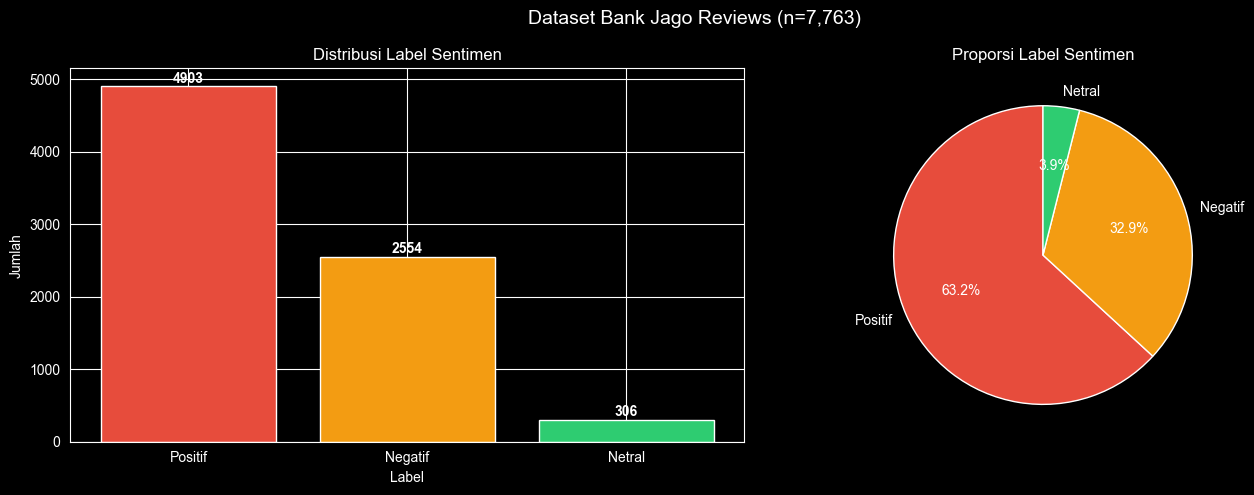

In [6]:
# Cell 6: Visualize final label distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

label_counts = df['label'].value_counts()
colors = ['#e74c3c', '#f39c12', '#2ecc71']

axes[0].bar(label_counts.index, label_counts.values, color=colors)
axes[0].set_title('Distribusi Label Sentimen')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Jumlah')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

axes[1].pie(label_counts.values, labels=label_counts.index,
            colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporsi Label Sentimen')

plt.suptitle(f'Dataset Bank Jago Reviews (n={len(df):,})', fontsize=14)
plt.tight_layout()
plt.savefig('data/label_distribution.png', dpi=150)
plt.show()

## Eksplorasi Data: Word Cloud & Top Kata

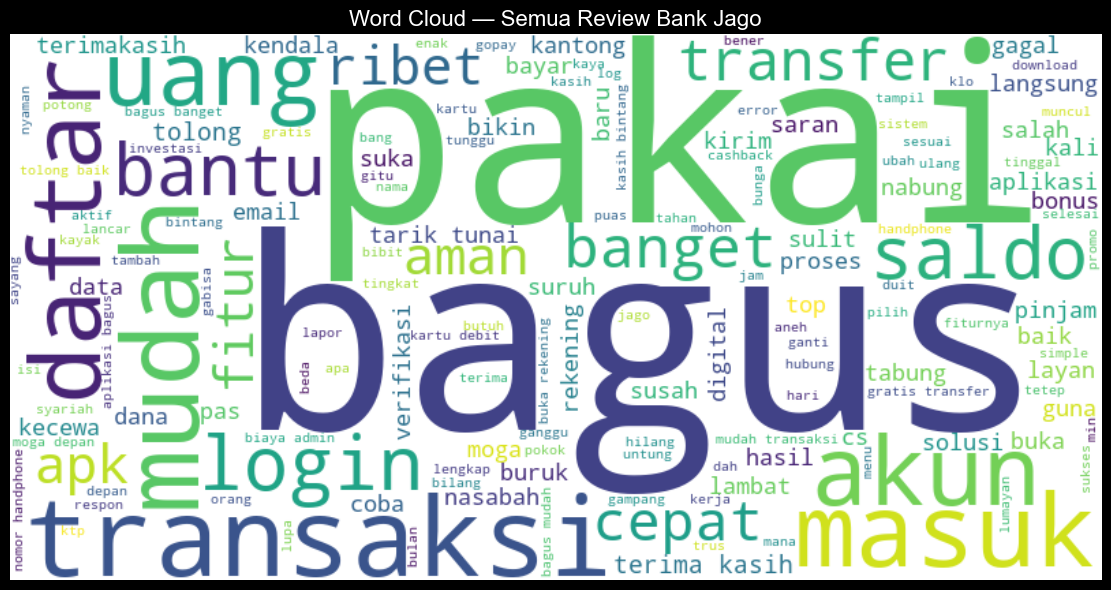

In [7]:
# Cell 7: Word Cloud — semua data
all_words = ' '.join(df['content_clean'].dropna().values)

wordcloud = WordCloud(width=800, height=400, background_color='white',
                      min_font_size=10, colormap='viridis').generate(all_words)

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Word Cloud — Semua Review Bank Jago', fontsize=16)
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
plt.tight_layout()
plt.savefig('data/wordcloud_all.png', dpi=150)
plt.show()

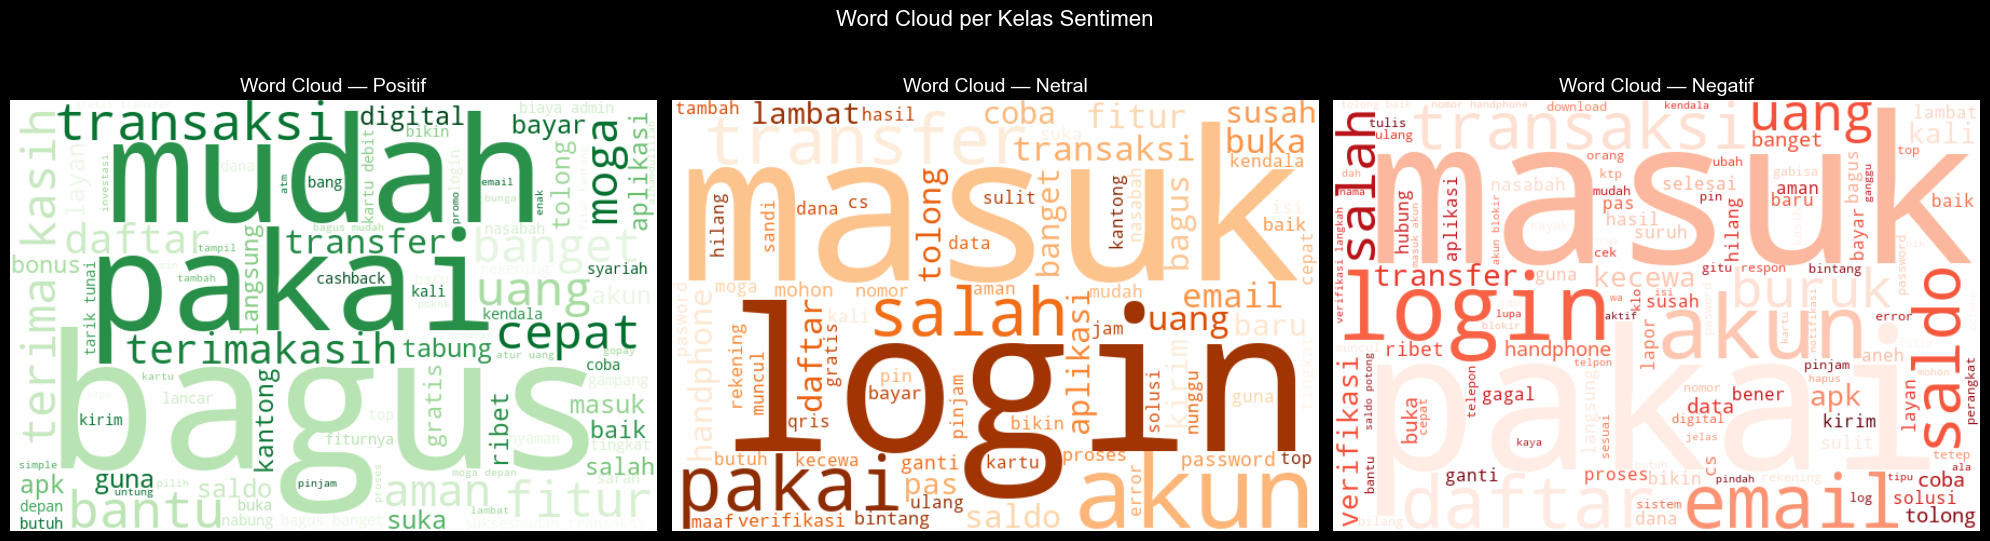

In [8]:
# Cell 8: Word Cloud per sentiment class
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
labels = ['Positif', 'Netral', 'Negatif']
colors_map = ['Greens', 'Oranges', 'Reds']

for ax, label, cmap in zip(axes, labels, colors_map):
    subset = df[df['label'] == label]['content_clean'].dropna()
    text = ' '.join(subset.values)
    if len(text.strip()) > 0:
        wc = WordCloud(width=600, height=400, background_color='white',
                       min_font_size=10, colormap=cmap).generate(text)
        ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'Word Cloud — {label}', fontsize=14)
    ax.axis('off')

plt.suptitle('Word Cloud per Kelas Sentimen', fontsize=16)
plt.tight_layout()
plt.savefig('data/wordcloud_per_sentiment.png', dpi=150)
plt.show()

C:\Users\ADVAN\AppData\Local\Temp\ipykernel_14220\1211461629.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='skor_tfidf', y='kata', data=tfidf_sums, palette='viridis')


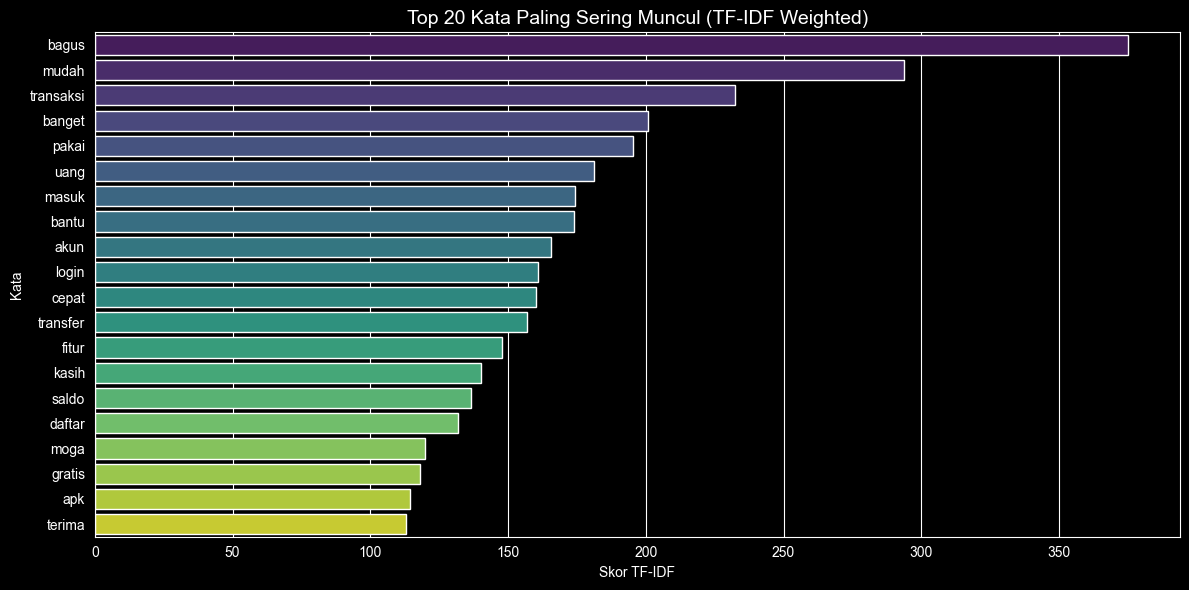

In [9]:
# Cell 9: Top 20 most frequent words (TF-IDF weighted)
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df['content_clean'].dropna())

tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_sums = tfidf_df.sum().reset_index()
tfidf_sums.columns = ['kata', 'skor_tfidf']
tfidf_sums = tfidf_sums.sort_values('skor_tfidf', ascending=False).head(20)

plt.figure(figsize=(12, 6))
sns.barplot(x='skor_tfidf', y='kata', data=tfidf_sums, palette='viridis')
plt.title('Top 20 Kata Paling Sering Muncul (TF-IDF Weighted)', fontsize=14)
plt.xlabel('Skor TF-IDF')
plt.ylabel('Kata')
plt.tight_layout()
plt.savefig('data/top20_tfidf_words.png', dpi=150)
plt.show()